<span style="font-size:2em; font-weight:bold;">Objective 2: Evaluation of Ground Motion Spatial Correlation in New Zealand Through Empirical Approaches - Case Study Data Creation</span>
***

This notebook was developed to create and export data necessary for carrying out case studies on New Zealand's three (3) most destructive earthquakes:

1) Darfield Earthquake
2) Christchurch Earthquake
3) Kaikoura Earthquake

# 1.0 Import Modules and Data

## 1.1 Import Modules

In [1]:
import os
os.environ["NUMBA_DISABLE_INTEL_SVML"] = "1"
import gc
import numpy as np
import pandas as pd
import pygmt
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
import rasterio

## 1.2 Import Data

### 1.2.1 Import and filter database

In [2]:
# Load NZ GMDB Flatfile
gm_im_table_50 = pd.read_csv(Path(r'D:\NZGMDB\NZGMDB_4p3_NGA\quality_flatfiles_4p3\ground_motion_im_table_rotd50_flat.csv'),low_memory=False)

# Remove non-IM information to optimize storage
gm_im_table_50.drop(gm_im_table_50.iloc[:,182:571],inplace=True,axis = 1)

# Remove Duplicates BUT with HN channels as priority
gm_im_table_50.sort_values('chan',ascending=False,inplace=True)
gm_im_table_50.drop_duplicates(subset=['evid','sta'],keep='first',inplace=True)
gm_im_table_50 = (gm_im_table_50.sort_values('datetime', ascending=True).reset_index(drop=True))

# Remove possible error values
gm_im_table_50 = gm_im_table_50[gm_im_table_50["pSA_0.01"]>0]

# Apply filters on the data
gm_im_table_50 = gm_im_table_50[gm_im_table_50.is_ground_level].reset_index(drop=True)

# append additional station parameters
stations = pd.read_csv(Path(r'D:\NZGMDB\NZGMDB_4p3\quality_flatfiles_4p3\site_table_TRI_multiscale_group_TWI.csv'))
stations.fillna(0,inplace=True)
stations_filt = pd.DataFrame()
stations_filt['sta'] = stations['sta']
stations_filt['TRI'] = stations['TRI']
gm_im_table_50 = gm_im_table_50.merge(stations_filt,on='sta',how='left')

# export
dar_evid = '3366146'
chc_evid = '3468575'
kai_evid = '2016p858000'

rupture_evids = [dar_evid, chc_evid, kai_evid]
gm_im_table_50 = gm_im_table_50[gm_im_table_50.evid.isin(rupture_evids)].reset_index(drop = True)

### 1.2.2 Earthquake source geometeries and hypocenters

In [3]:
h5py_directory = Path(r'C:\Users\LEGION\OneDrive - University of Canterbury\spatial_correlations\BB2023\AJR_NZGMDB_EASZT\esup_data\case_study')

earthquake_source_geom = pd.read_csv(Path(r'D:\NZGMDB\NZGMDB_4p3_NGA\quality_flatfiles_4p3\earthquake_source_geometry.csv'))
earthquake_source_geom_filt = earthquake_source_geom[earthquake_source_geom.evid.isin(rupture_evids)].reset_index(drop = True)
hyp_depth_map = {
    "3366146": 5.89465,
    "3468575": 4.86967,
    "2016p858000": 8.9271
}

mag_map = {
    "3366146": gm_im_table_50[gm_im_table_50.evid=='3366146'].mag.iloc[0],
    "3468575": gm_im_table_50[gm_im_table_50.evid=='3468575'].mag.iloc[0],
    "2016p858000": gm_im_table_50[gm_im_table_50.evid=='2016p858000'].mag.iloc[0]
}
earthquake_source_geom_filt["hyp_depth"] = earthquake_source_geom_filt["evid"].map(hyp_depth_map)
earthquake_source_geom_filt["mag"] = earthquake_source_geom_filt["evid"].map(mag_map)

# update ev_lat/lons with hypocenters from earthquake_geometry
lat_map = earthquake_source_geom_filt.drop_duplicates('evid').set_index('evid')['hyp_lat']
lon_map = earthquake_source_geom_filt.drop_duplicates('evid').set_index('evid')['hyp_lon']

gm_im_table_50['ev_lat'] = gm_im_table_50['evid'].map(lat_map).combine_first(gm_im_table_50['ev_lat'])
gm_im_table_50['ev_lon'] = gm_im_table_50['evid'].map(lon_map).combine_first(gm_im_table_50['ev_lon'])

### 1.2.3 Build corners from geometry

#### 1.2.3.1 Function

In [4]:
def build_corners(df):
    """
    Construct corners arrays grouped by evid.
    Returns dict: {evid: np.ndarray of shape (4, 3, n_planes)}
    where axes are (plane, [lon, lat, depth], corner_index).
    """
    result = {}
    for evid, g in df.groupby("evid"):
        plane_blocks = []
        for _, row in g.iterrows():
            lats   = [row[f"corner_{i}_lat"]   for i in range(4)]
            lons   = [row[f"corner_{i}_lon"]   for i in range(4)]
            depths = [row[f"corner_{i}_depth"] for i in range(4)]
            arr = np.vstack([lons, lats, depths])  # (3,4)
            plane_blocks.append(arr)

        # stack planes → (4, 3, n_planes)
        arr = np.stack(plane_blocks)
        arr = np.transpose(arr, (2, 1, 0))

        result[evid] = arr
    return result

#### 1.2.3.2 Build planes

In [5]:
corners_dict = build_corners(earthquake_source_geom_filt)

### 1.2.5 load risk results

In [6]:
chcchc_risk = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\chcchc_loss_exceedance_all_models.csv')
darchc_risk = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\darchc_loss_exceedance_all_models.csv')
kaiwel_risk = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\kaiwel_loss_exceedance_all_models.csv')

chcchc_risk_reg = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\loss_exceedance_all_models_chchc_grp2.csv')
darchc_risk_reg = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\loss_exceedance_all_models_darchc_grp2.csv')
kaiwel_risk_reg = pd.read_csv(r'C:\Users\LEGION\OneDrive\PhD Documents\Research\Papers\paper 1\risk\openquake_chc_wel\loss_exceedance_all_models_kaiwel_grp1.csv')

### 1.2.6 Plot All Ruptures

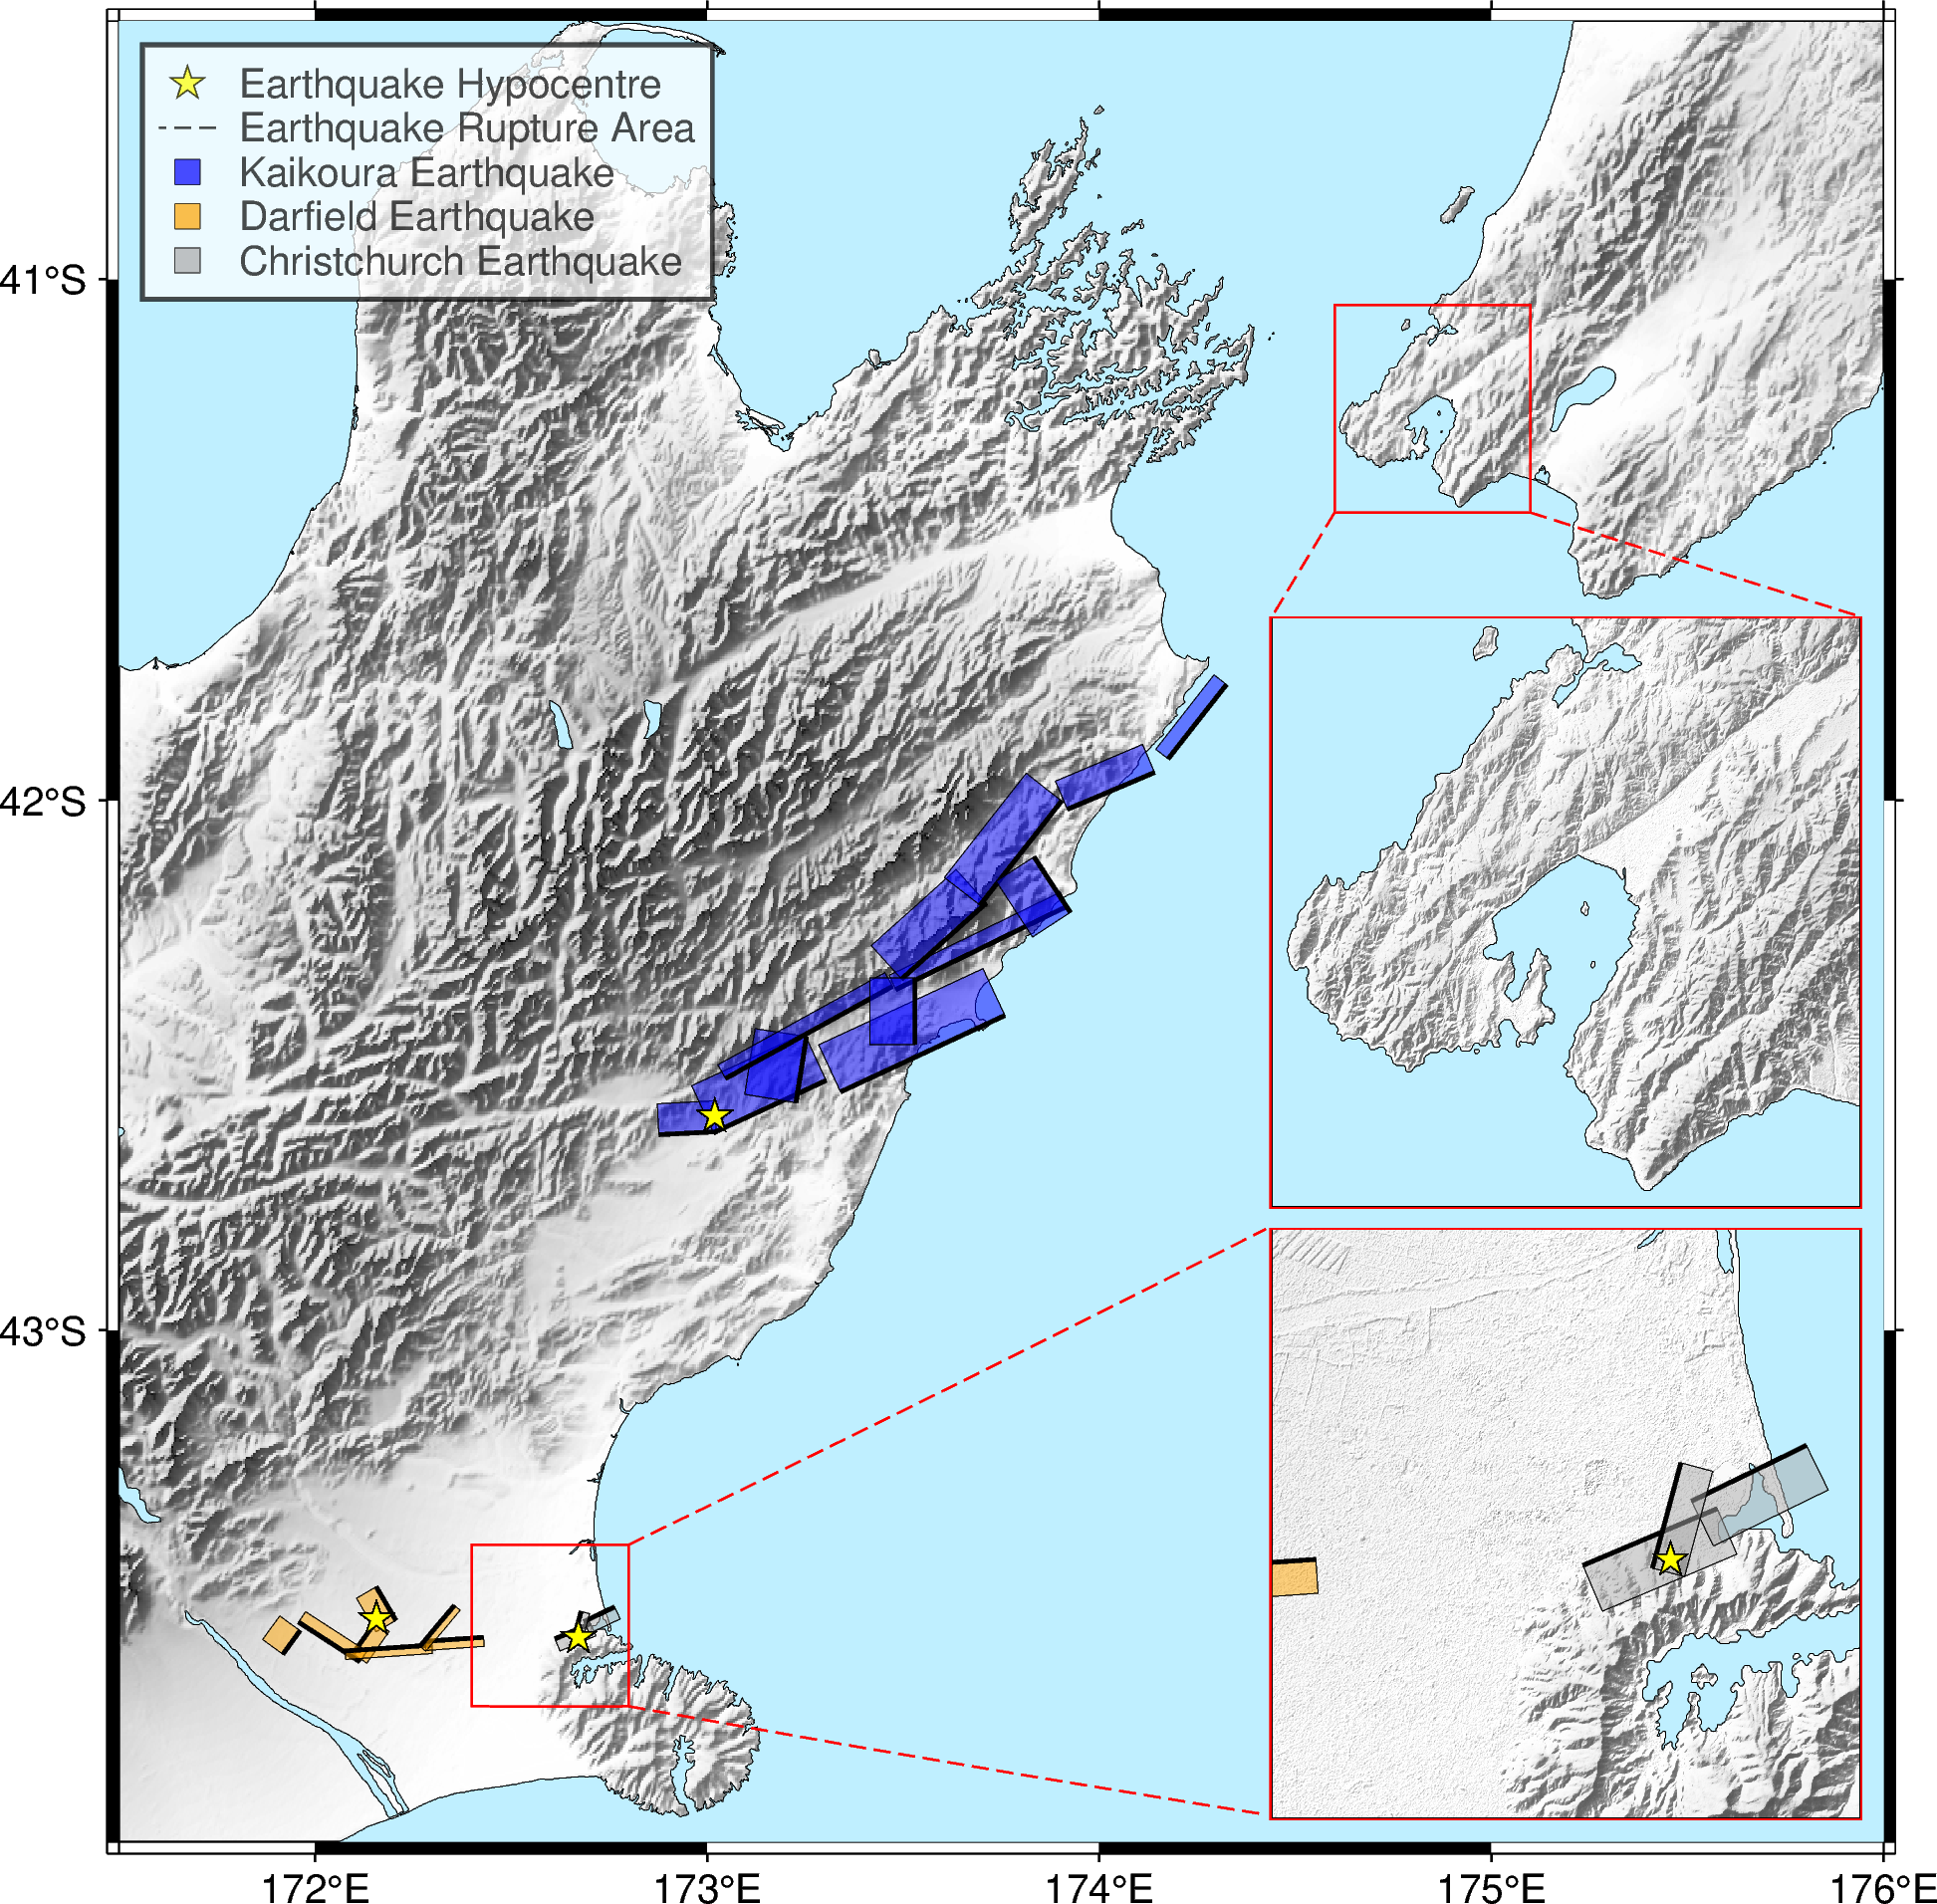

In [7]:
region = [171.5, 176, -43.95, -40.5]

grid = pygmt.datasets.load_earth_relief(resolution="15s",region=region)
fig = pygmt.Figure()
pygmt.makecpt(cmap="gray", series=[0, 2000, 20], reverse = True)
fig.grdimage(grid=grid, projection="M15c", frame="a",cmap = True, shading = True, region = region)
fig.coast(shorelines="0.15p,black", water = 'lightblue1', region=region)

# Process each fault plane
rup_colors = ["blue", "orange", "darkgray"]
for i, (evid, corners) in enumerate(corners_dict.items()):
    n_planes = corners.shape[2]   # number of planes is last dimension
    for ix in range(n_planes):
        cur_corners = corners[:, :, ix]

        # Draw the outline (close polygon)
        fig.plot(
            x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
            y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
            close=True,pen="0.1p,black",fill=f"{rup_colors[i]}@50")

        # Draw the top edge (shallowest two corners by depth)
        cur_sort_ind = np.argsort(cur_corners[:, 2])
        fig.plot(
            x=cur_corners[cur_sort_ind[:2], 0],
            y=cur_corners[cur_sort_ind[:2], 1],
            pen="1.0p,black", projection="M15c"
        )

# Plot hyponcenters
for evid in earthquake_source_geom_filt.evid:
    fig.plot(
        x=earthquake_source_geom_filt.hyp_lon,
        y=earthquake_source_geom_filt.hyp_lat,
        style="a0.3c",
        pen="black",
        fill="yellow1",
        projection="M15c",
        )

# Define inset regions
inset_regions = {
    "inset1": [172.4, 172.80, -43.7, -43.4],
    "inset2": [174.6, 175.10, -41.45, -41.05],
}

# Helper to draw a rectangular box
def draw_box(fig, reg, **kwargs):
    x0, x1, y0, y1 = reg
    xs = [x0, x1, x1, x0, x0]
    ys = [y0, y0, y1, y1, y0]
    fig.plot(x=xs, y=ys, **kwargs)

# Draw boxes on the main map
for reg in inset_regions.values():
    draw_box(fig, reg, pen="0.5p,red")

# First inset
with fig.inset(position="jBR+o0.2c/0.2c+w5.0c/5.0c", box="+p1p,red"):
    grid_inset1 = pygmt.datasets.load_earth_relief(resolution="01s", region=inset_regions["inset1"])
    fig.grdimage(grid=grid_inset1, projection="M5c", cmap=True, shading=True, frame="f", region=inset_regions["inset1"])
    fig.coast(region=inset_regions["inset1"], projection="M5c",shorelines="0.15p,black", water="lightblue1", frame="f")

    # Process each fault plane
    rup_colors = ["blue", "orange", "darkgray", "purple"]
    for i, (evid, corners) in enumerate(corners_dict.items()):
        n_planes = corners.shape[2]   # number of planes is last dimension
        for ix in range(n_planes):
            cur_corners = corners[:, :, ix]

            # Draw the outline (close polygon)
            fig.plot(
                x=cur_corners[:, 0].tolist() + [cur_corners[0, 0]],
                y=cur_corners[:, 1].tolist() + [cur_corners[0, 1]],
                close=True,pen="0.1p,black",fill=f"{rup_colors[i]}@50", projection="M5c")

            # Draw the top edge (shallowest two corners by depth)
            cur_sort_ind = np.argsort(cur_corners[:, 2])
            fig.plot(
                x=cur_corners[cur_sort_ind[:2], 0],
                y=cur_corners[cur_sort_ind[:2], 1],
                pen="1.0p,black", projection="M5c"
            )

    # plot hypocenters
    for evid in earthquake_source_geom_filt.evid:
        fig.plot(
            x=earthquake_source_geom_filt.hyp_lon,
            y=earthquake_source_geom_filt.hyp_lat,
            style="a0.3c",
            pen="black",
            fill="yellow1",
            projection="M5c",
            )

# Second inset
with fig.inset(position="jBR+o0.2c/5.4c+w5.0c/5.0c", box="+p1p,red"):
    grid_inset2 = pygmt.datasets.load_earth_relief(resolution="01s", region=inset_regions["inset2"])
    fig.grdimage(grid=grid_inset2, projection="M5c", cmap=True, shading=True, frame="f", region=inset_regions["inset2"])
    fig.coast(region=inset_regions["inset2"], projection="M5c",shorelines="0.15p,black", water="lightblue1", frame="f")

# connect lines
fig.plot(x=[172.80, 174.425],y=[-43.7, -43.9],pen="0.5p,red,-",projection="M15c")
fig.plot(x=[172.80, 174.425],y=[-43.4, -42.81],pen="0.5p,red,-",projection="M15c")
fig.plot(x=[175.10, 175.945],y=[-41.45, -41.65],pen="0.5p,red,-",projection="M15c")
fig.plot(x=[174.6, 174.44],y=[-41.45, -41.65],pen="0.5p,red,-",projection="M15c")

# dummy labels for legend
fig.plot(x=[0], y=[0], style="a0.3c", fill="yellow1", pen="black", label="Earthquake Hypocentre")
fig.plot(x=[0, 0], y=[0, 0], pen="0.5p,black,-", label="Earthquake Rupture Area")
fig.plot(x=[0], y=[0], style="s0.3c", pen="0.1p,black",fill="blue@30",label="Kaikoura Earthquake")
fig.plot(x=[0], y=[0], style="s0.3c", pen="0.1p,black",fill="orange@30",label="Darfield Earthquake")
fig.plot(x=[0], y=[0], style="s0.3c", pen="0.1p,black",fill="darkgray@30",label="Christchurch Earthquake")

fig.legend(position="jTL+o0.2c", box='+gwhite+p1p', transparency=30)
# Add colorbar for residuals only
# fig.colorbar(position="JMR+o0.5c/0c+w10c/0.4c", frame='af+lSpectral Acceleration, SA (1s) [g]')

# Show in notebook
fig.show(method='notebook', dpi=300, width=540)

# 2.0 Risk/Portfolio Losses

## 2.1 NZ-Wide SCM

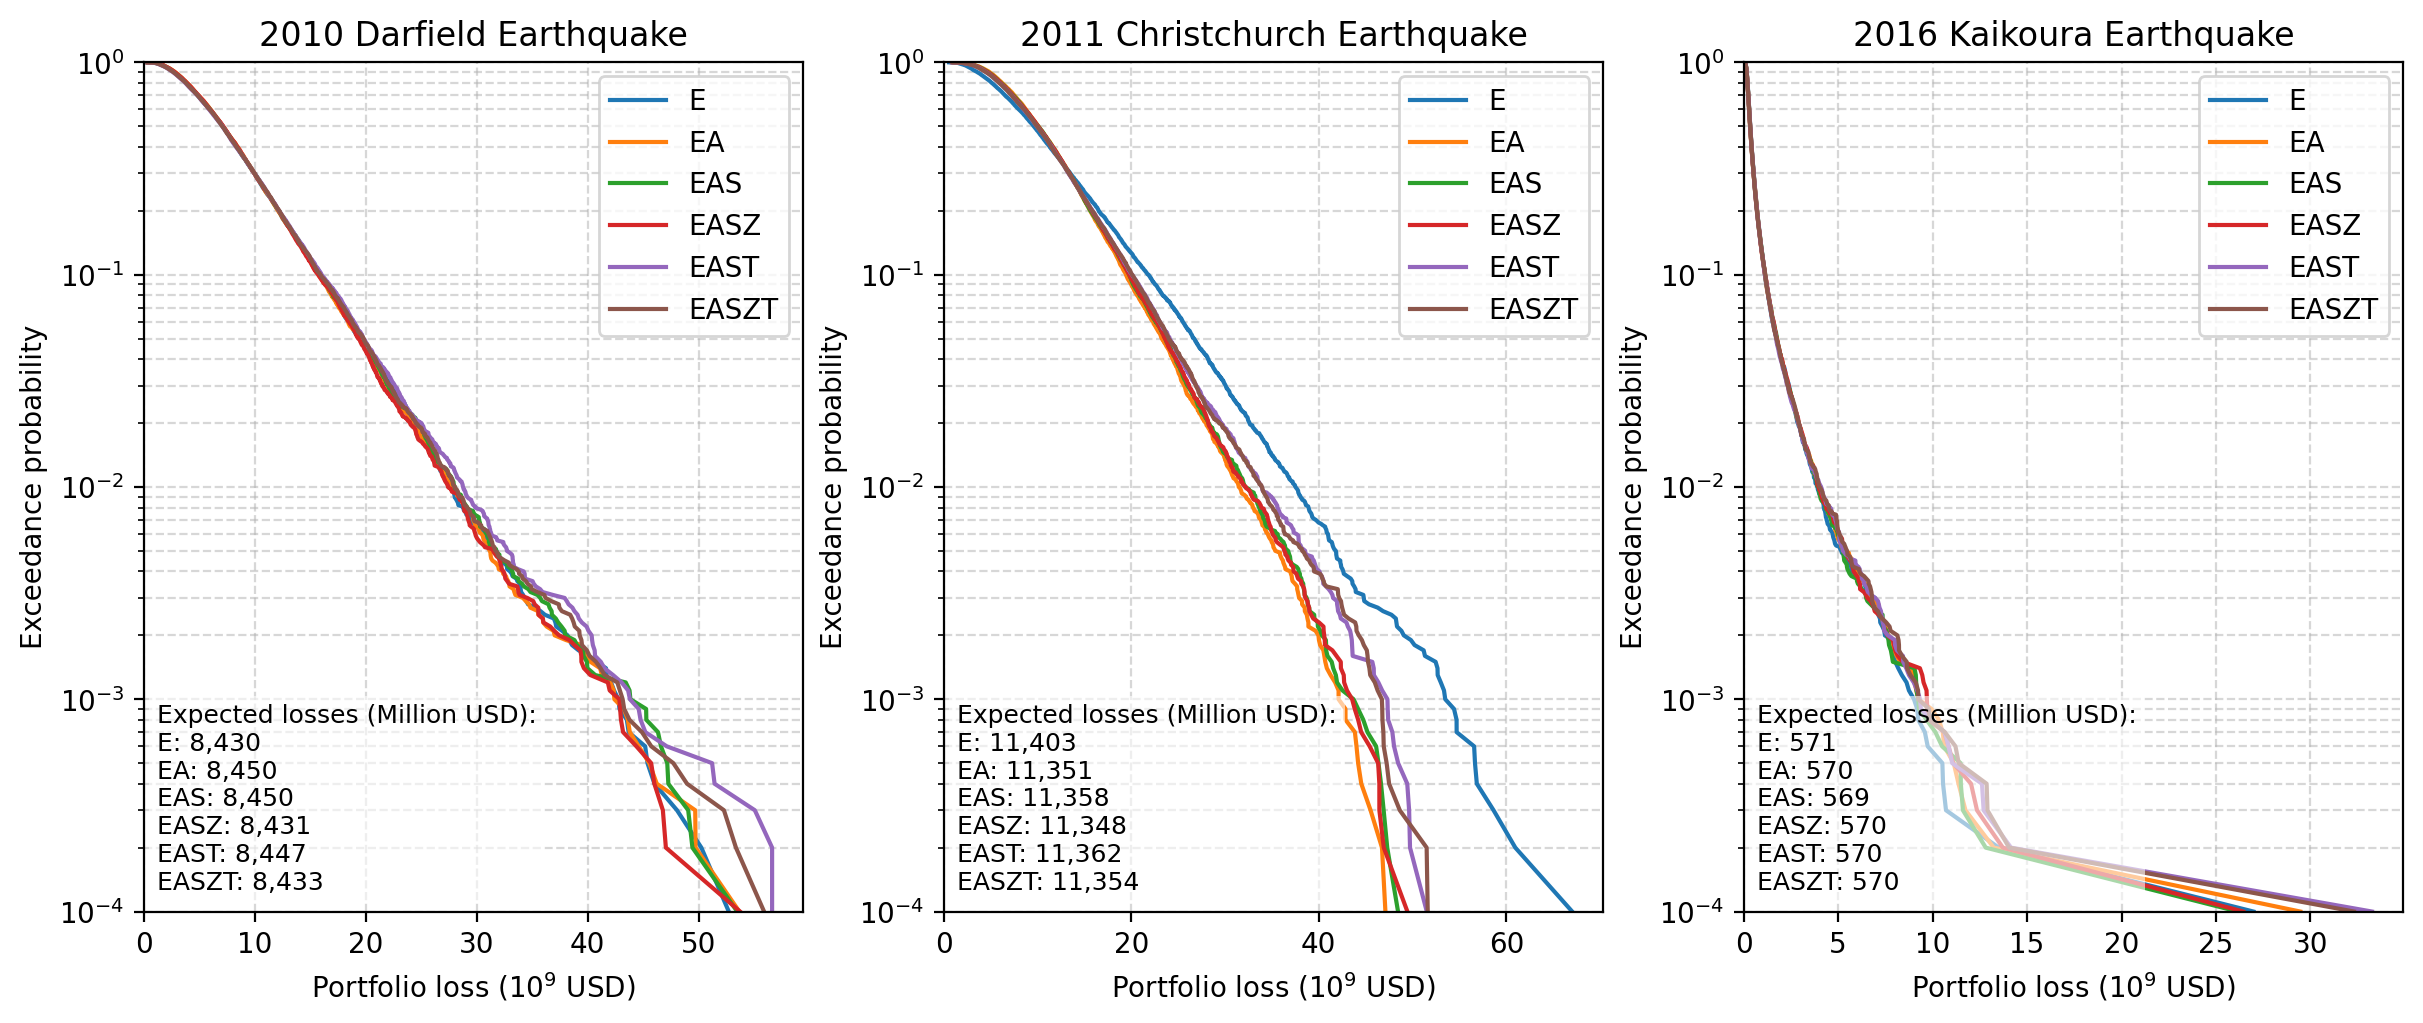

In [8]:
models = ['RA26E','RA26EA','RA26EAS','RA26EASZ','RA26EAST','RA26EASZT']
display_names = {
    "RA26E": "E",
    "RA26EA": "EA",
    "RA26EAS": "EAS",
    "RA26EASZ": "EASZ",
    "RA26EAST": "EAST",
    "RA26EASZT": "EASZT"
}

risk_results = [darchc_risk, chcchc_risk, kaiwel_risk]
titles = ["2010 Darfield Earthquake", "2011 Christchurch Earthquake", "2016 Kaikoura Earthquake"]

fig, ax = plt.subplots(1, 3, figsize=(12, 5), dpi=200, constrained_layout=True)

for i, risk_df in enumerate(risk_results):

    expected_losses = {}

    for model in models:
        df = risk_df[risk_df.model == model].reset_index(drop=True)
        df = df.sort_values("loss")
        loss = df["loss"].values
        ep   = df["exceedance_probability"].values

        # Expected annual loss
        eal = ((ep[:-1] - ep[1:]) * loss[:-1]).sum()
        expected_losses[model] = eal

        # Use display name in legend
        ax[i].plot(loss / 1e9, ep, label=display_names[model])

    # Panel formatting
    ax[i].set_title(titles[i], fontsize=12)
    ax[i].set_xlabel(r"Portfolio loss ($10^9$ USD)")
    ax[i].set_ylabel("Exceedance probability")
    ax[i].grid(True, which="both", linestyle="--", alpha=0.5)
    ax[i].set_yscale("log")
    ax[i].set_xlim(0, None)
    ax[i].set_ylim(1e-4, 1)
    ax[i].legend(fontsize=10)

    # Text box with display names
    loss_text = "Expected losses (Million USD):\n" + "\n".join(
        f"{display_names[model]}: {expected_losses[model] / 1e6:,.0f}"
        for model in models
    )

    ax[i].text(
        0.02, 0.02, loss_text,
        transform=ax[i].transAxes,
        fontsize=9,
        va="bottom",
        ha="left",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=3)
    )

plt.show()


## 2.2 Regional SCM

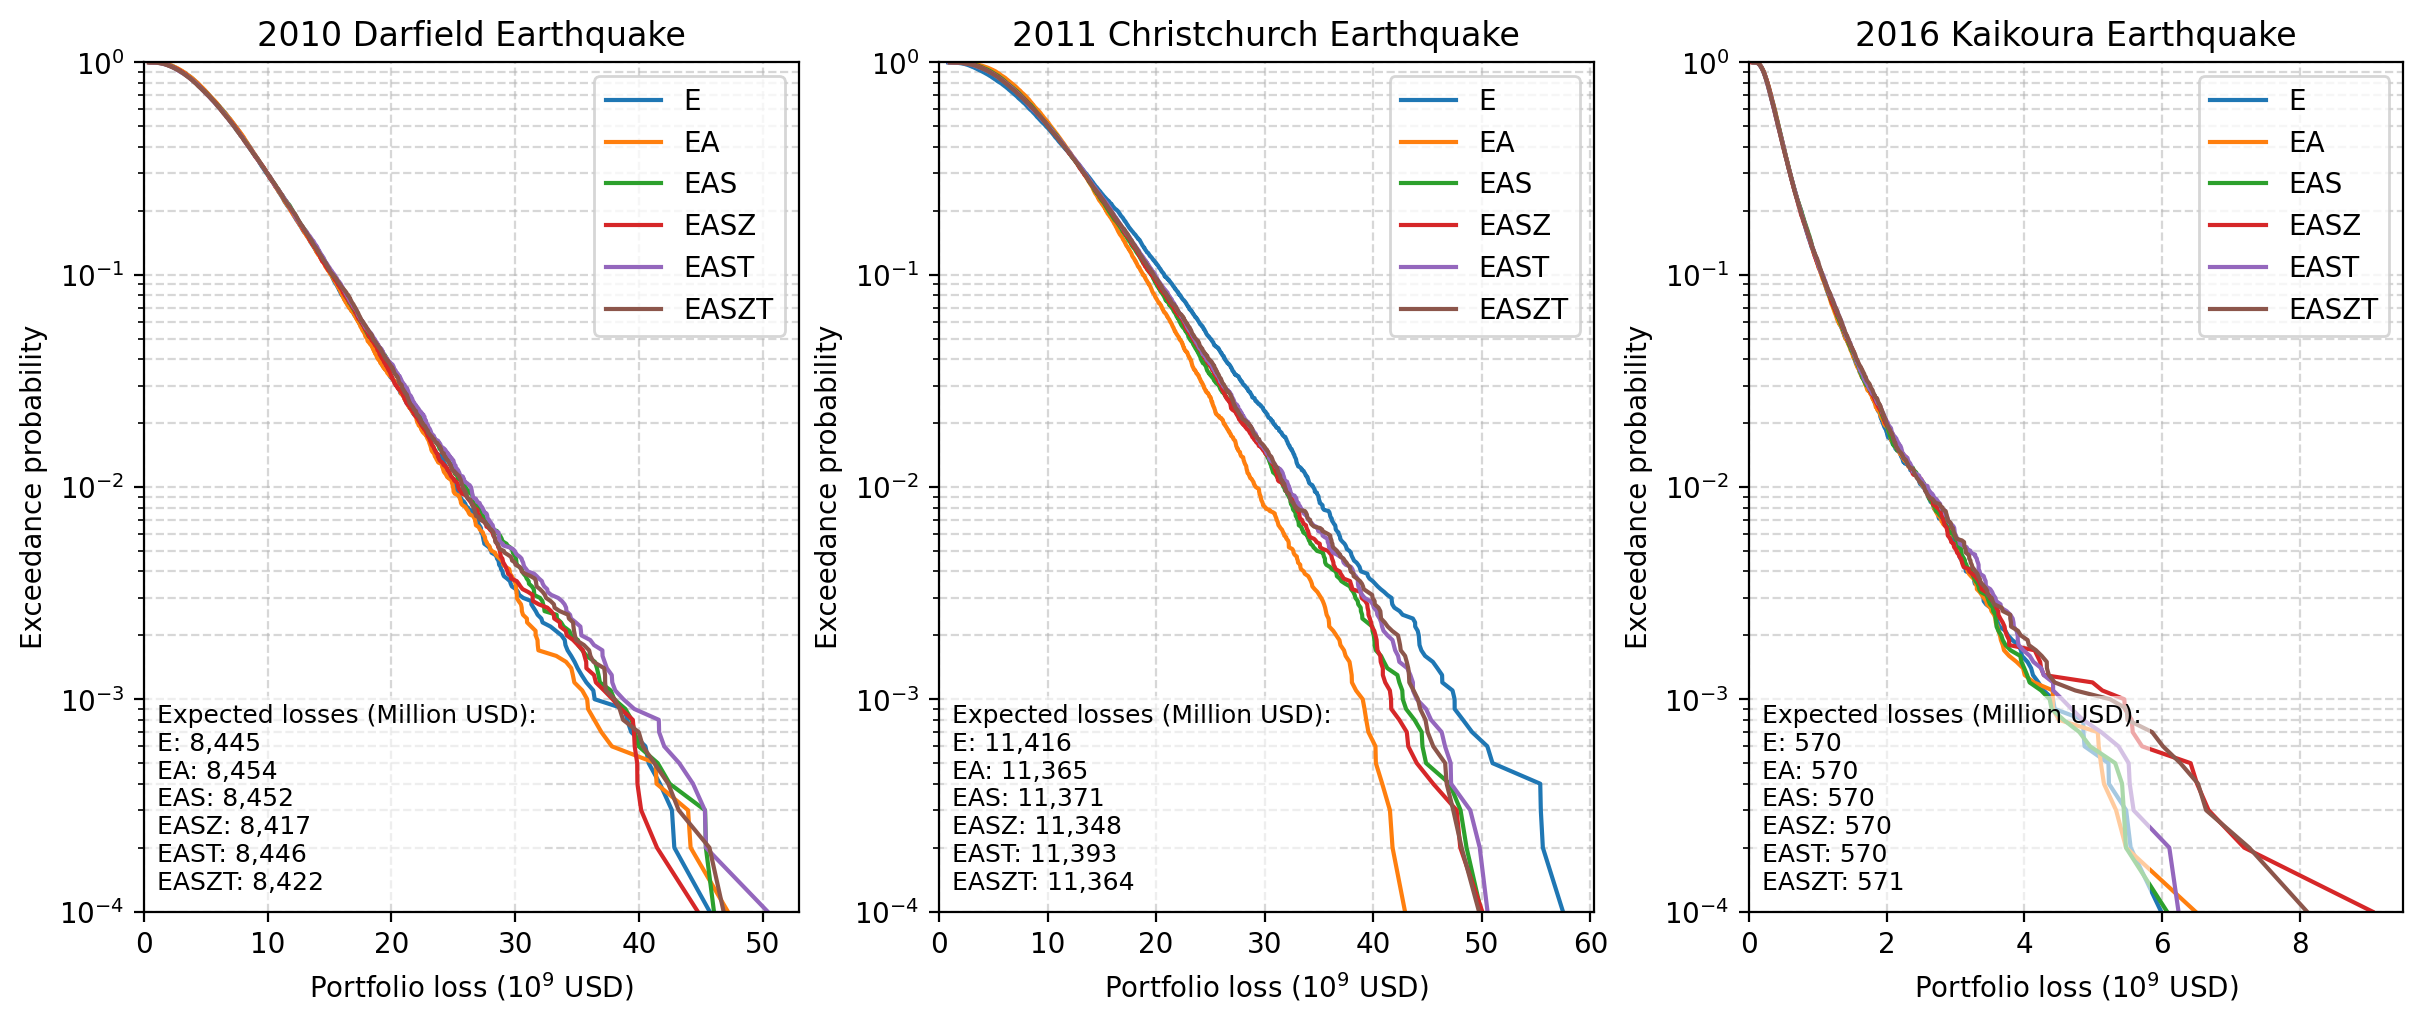

In [9]:
models = ['RA26E','RA26EA','RA26EAS','RA26EASZ','RA26EAST','RA26EASZT']
display_names = {
    "RA26E": "E",
    "RA26EA": "EA",
    "RA26EAS": "EAS",
    "RA26EASZ": "EASZ",
    "RA26EAST": "EAST",
    "RA26EASZT": "EASZT"
}

risk_results = [darchc_risk_reg, chcchc_risk_reg, kaiwel_risk_reg]
titles = ["2010 Darfield Earthquake", "2011 Christchurch Earthquake", "2016 Kaikoura Earthquake"]

fig, ax = plt.subplots(1, 3, figsize=(12, 5), dpi=200, constrained_layout=True)

for i, risk_df in enumerate(risk_results):

    expected_losses = {}

    for model in models:
        df = risk_df[risk_df.model == model].reset_index(drop=True)
        df = df.sort_values("loss")
        loss = df["loss"].values
        ep   = df["exceedance_probability"].values

        # Expected annual loss
        eal = ((ep[:-1] - ep[1:]) * loss[:-1]).sum()
        expected_losses[model] = eal

        # Use display name in legend
        ax[i].plot(loss / 1e9, ep, label=display_names[model])

    # Panel formatting
    ax[i].set_title(titles[i], fontsize=12)
    ax[i].set_xlabel(r"Portfolio loss ($10^9$ USD)")
    ax[i].set_ylabel("Exceedance probability")
    ax[i].grid(True, which="both", linestyle="--", alpha=0.5)
    ax[i].set_yscale("log")
    ax[i].set_xlim(0, None)
    ax[i].set_ylim(1e-4, 1)
    ax[i].legend(fontsize=10)

    # Text box with display names
    loss_text = "Expected losses (Million USD):\n" + "\n".join(
        f"{display_names[model]}: {expected_losses[model] / 1e6:,.0f}"
        for model in models
    )

    ax[i].text(
        0.02, 0.02, loss_text,
        transform=ax[i].transAxes,
        fontsize=9,
        va="bottom",
        ha="left",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=3)
    )

plt.show()
